# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the Iris Dataset

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)
print("Dataset Shape:", X.shape)

Dataset loaded successfully!
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Dataset Shape: (150, 4)


# Display the Dataset

In [3]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = iris.target_names[y]

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


# Check Dataset Information

In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Species"].value_counts())

Number of Rows: 150
Number of Columns: 5

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64

Class Distribution:
Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# Visualize the Dataset

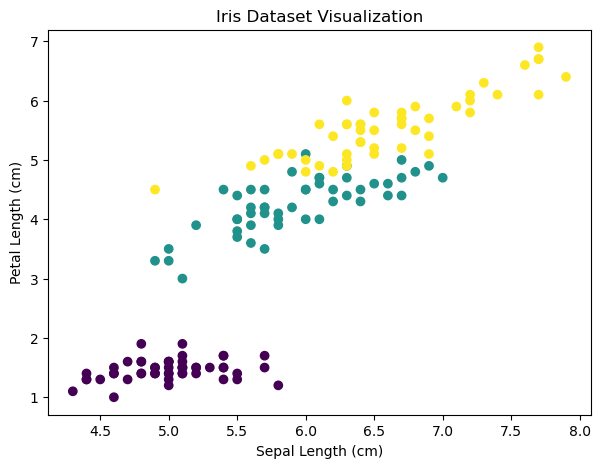

In [5]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 2], c=y)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Iris Dataset Visualization")

plt.show()

# Split the Dataset into Training and Testing Sets

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 120
Testing Samples: 30


# Normalize the Features

In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


# Build and Train the Neural Network

In [8]:
model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    random_state=42
)

model.fit(X_train, y_train)

print("Neural Network trained successfully!")

Neural Network trained successfully!


# Predict the Flower Classes

In [9]:
y_pred = model.predict(X_test)

print("Actual Classes:")
print(iris.target_names[y_test])

print("\nPredicted Classes:")
print(iris.target_names[y_pred])

Actual Classes:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']

Predicted Classes:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


# Calculate Model Accuracy

In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 96.67 %


# Display the Classification Report

In [11]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# Display the Confusion Matrix

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


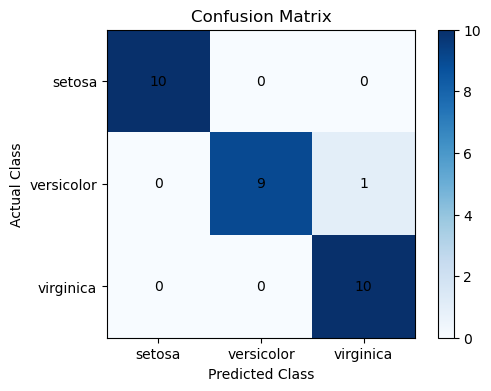

In [12]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

# Test the Model with a New Flower

In [13]:
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

new_flower = scaler.transform(new_flower)

prediction = model.predict(new_flower)

print("Predicted Flower Species:", iris.target_names[prediction[0]])

Predicted Flower Species: setosa
